# 06 — Business Impact

Phase 4, notebook 3 of 3. Decile lift, a campaign-simulation business
case, a sensitivity check on the illustrative economics, and a concrete
A/B test design -- all built on the primary model from Notebook 05
(`LogisticRegression(class_weight="balanced")`, test PR-AUC reported
there) and `config/config.yaml`'s retention economics.

In [1]:
import os
import sys
sys.path.insert(0, "../src")

import decimal
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from dateutil.relativedelta import relativedelta
from sqlalchemy import text

from churn.config import PROJECT_ROOT, get_app_config

os.chdir(PROJECT_ROOT)

from churn.db.engine import get_engine

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)


def coerce_decimal_columns(frame: pd.DataFrame) -> pd.DataFrame:
    for c in frame.columns:
        if frame[c].dtype == object and frame[c].map(lambda v: isinstance(v, decimal.Decimal)).any():
            frame[c] = pd.to_numeric(frame[c], errors="coerce")
    return frame


cfg = get_app_config()
RANDOM_SEED = cfg.synthetic.random_seed
engine = get_engine()

panel = pd.read_sql(
    text("SELECT * FROM feature_snapshots WHERE feature_set_version = :v"),
    engine,
    params={"v": cfg.feature_set.version},
)
panel["reference_date"] = pd.to_datetime(panel["reference_date"])
panel = coerce_decimal_columns(panel)

snapshot_ts = pd.Timestamp(cfg.data.snapshot_date)
modeling_panel = panel[panel["reference_date"] < snapshot_ts].copy()

with open(PROJECT_ROOT / "config" / "selected_features_v1.yaml", encoding="utf-8") as fh:
    selected_features = yaml.safe_load(fh)["selected_features"]

panel_start = pd.Timestamp(cfg.data.panel_start_date)
train_end = panel_start + relativedelta(months=cfg.data.train_months)
val_end = train_end + relativedelta(months=cfg.data.validation_months)
test_end = val_end + relativedelta(months=cfg.data.test_months)

train_df = modeling_panel[modeling_panel["reference_date"] < train_end]
val_df = modeling_panel[(modeling_panel["reference_date"] >= train_end) & (modeling_panel["reference_date"] < val_end)]
test_df = modeling_panel[(modeling_panel["reference_date"] >= val_end) & (modeling_panel["reference_date"] < test_end)]
trainval_df = pd.concat([train_df, val_df])

## 1. Refit the primary model (same as Notebook 05)

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_features = [
    c for c in selected_features
    if not (pd.api.types.is_numeric_dtype(modeling_panel[c]) and not pd.api.types.is_bool_dtype(modeling_panel[c]))
]
num_features = [c for c in selected_features if c not in cat_features]
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("num", StandardScaler(), num_features),
])

X_trainval, y_trainval = trainval_df[selected_features], trainval_df["label_churn_next_30d"].astype(int)
X_test, y_test = test_df[selected_features], test_df["label_churn_next_30d"].astype(int)

logreg = SkPipeline([("prep", preprocessor), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED))])
logreg.fit(X_trainval, y_trainval)
proba = logreg.predict_proba(X_test)[:, 1]
print(f"Test PR-AUC: {average_precision_score(y_test, proba):.4f}  |  n={len(test_df)}, positives={y_test.sum()}")

Test PR-AUC: 0.1093  |  n=10328, positives=163


## 2. Decile lift

Sort test customers by predicted churn probability, split into 10
equal-sized deciles, and check whether the model actually concentrates
churners into the top deciles -- the practical question a retention team
asks before trusting any AUC number.

,decile,n,churners,churn_rate,lift
0,0,1033,73,0.070668,4.477661
1,1,1033,31,0.030010,1.901472
2,2,1033,20,0.019361,1.226756
3,3,1032,11,0.010659,0.675370
4,4,1033,11,0.010649,0.674716
5,5,1033,7,0.006776,0.429365
6,6,1032,4,0.003876,0.245589
7,7,1033,6,0.005808,0.368027
8,8,1033,0,0.000000,0.000000
9,9,1033,0,0.000000,0.000000


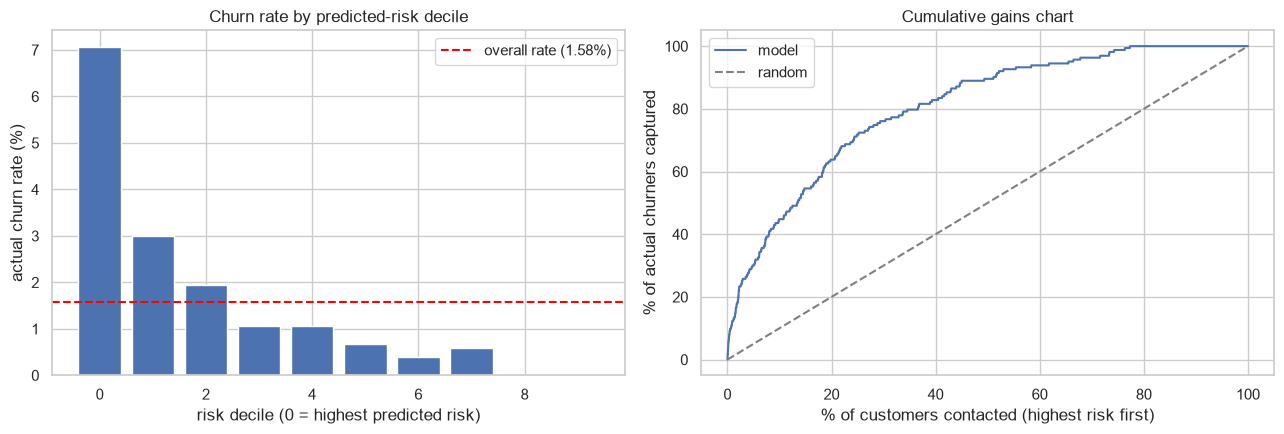

Top decile: 7.07% actual churn rate vs. 1.58% overall -- 4.5x lift.


In [3]:
lift_df = pd.DataFrame({"proba": proba, "actual": y_test.to_numpy()})
lift_df["decile"] = pd.qcut(lift_df["proba"], 10, labels=False, duplicates="drop")
lift_df["decile"] = lift_df["decile"].max() - lift_df["decile"]  # 0 = highest-risk decile

decile_summary = lift_df.groupby("decile").agg(
    n=("actual", "size"), churners=("actual", "sum"), churn_rate=("actual", "mean"),
).reset_index()
overall_rate = y_test.mean()
decile_summary["lift"] = decile_summary["churn_rate"] / overall_rate
display(decile_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(decile_summary["decile"], decile_summary["churn_rate"] * 100)
axes[0].axhline(overall_rate * 100, color="red", linestyle="--", label=f"overall rate ({100*overall_rate:.2f}%)")
axes[0].set_xlabel("risk decile (0 = highest predicted risk)")
axes[0].set_ylabel("actual churn rate (%)")
axes[0].set_title("Churn rate by predicted-risk decile")
axes[0].legend()

lift_df_sorted = lift_df.sort_values("proba", ascending=False).reset_index(drop=True)
lift_df_sorted["cum_churners_pct"] = lift_df_sorted["actual"].cumsum() / lift_df_sorted["actual"].sum() * 100
lift_df_sorted["cum_customers_pct"] = (lift_df_sorted.index + 1) / len(lift_df_sorted) * 100
axes[1].plot(lift_df_sorted["cum_customers_pct"], lift_df_sorted["cum_churners_pct"], label="model")
axes[1].plot([0, 100], [0, 100], linestyle="--", color="gray", label="random")
axes[1].set_xlabel("% of customers contacted (highest risk first)")
axes[1].set_ylabel("% of actual churners captured")
axes[1].set_title("Cumulative gains chart")
axes[1].legend()
plt.tight_layout()
plt.show()

top_decile = decile_summary.iloc[0]
print(f"Top decile: {top_decile['churn_rate']*100:.2f}% actual churn rate vs. {100*overall_rate:.2f}% overall "
      f"-- {top_decile['lift']:.1f}x lift.")

## 3. Campaign simulation

Compares four concrete strategies on the test set using the same
expected-value formula as Notebook 05
(`offer_success_rate * LTV - retention_offer_cost` per true positive,
`-retention_offer_cost` per false positive): **contact no one**, **contact
everyone**, **the configured `risk_bands.medium_max` threshold**, and
**the business-optimal threshold found in Notebook 05**.

In [4]:
biz = cfg.business
ltv_proxy = test_df["monthly_charges"].astype(float).to_numpy() * biz.assumed_ltv_horizon_months
y_true = y_test.to_numpy()


def strategy_value(threshold: float) -> dict:
    flagged = proba >= threshold
    tp = flagged & (y_true == 1)
    fp = flagged & (y_true == 0)
    value = float(np.sum(biz.offer_success_rate * ltv_proxy[tp] - biz.retention_offer_cost) - biz.retention_offer_cost * fp.sum())
    return {
        "n_contacted": int(flagged.sum()),
        "true_positives": int(tp.sum()),
        "false_positives": int(fp.sum()),
        "expected_retained": round(biz.offer_success_rate * tp.sum(), 1),
        "expected_value": round(value, 2),
    }


# Recompute the business-optimal threshold the same way Notebook 05 did.
thresholds_grid = np.linspace(0.0, 1.0, 201)
grid_values = [strategy_value(t)["expected_value"] for t in thresholds_grid]
business_optimal_threshold = float(thresholds_grid[int(np.argmax(grid_values))])

strategies = {
    "contact_no_one": strategy_value(1.01),
    "contact_everyone": strategy_value(0.0),
    f"risk_bands.medium_max ({biz.risk_bands.medium_max})": strategy_value(biz.risk_bands.medium_max),
    f"business_optimal ({business_optimal_threshold:.3f})": strategy_value(business_optimal_threshold),
}
strategy_df = pd.DataFrame(strategies).T
display(strategy_df)
print(f"\nBest strategy: {strategy_df['expected_value'].idxmax()} "
      f"(${strategy_df['expected_value'].max():,.0f} on this {len(test_df)}-row, "
      f"{(test_df['reference_date'].max()-test_df['reference_date'].min()).days+30}-day test window)")

n_repeat_customers = test_df["customer_id"].duplicated().sum()
best_flagged_customers = test_df.loc[proba >= business_optimal_threshold, "customer_id"]
n_repeats_in_best = best_flagged_customers.duplicated().sum()
print(f"\nCaveat: rows here are panel-rows, not distinct customers -- {n_repeat_customers} customers appear "
      f"in both test-window months. At the business-optimal threshold, {n_repeats_in_best} of "
      f"{len(best_flagged_customers)} flagged rows are a repeat customer, so that row is essentially exact; "
      f"the contact_everyone / risk_bands.medium_max rows double-count every repeat customer's LTV, "
      f"inflating their (already negative) totals somewhat.")

,n_contacted,true_positives,false_positives,expected_retained,expected_value
contact_no_one,0.0,0.0,0.0,0.0,0.00
contact_everyone,10328.0,163.0,10165.0,48.9,-474973.36
risk_bands.medium_max (0.7),1383.0,81.0,1302.0,24.3,-48267.30
business_optimal (0.940),34.0,13.0,21.0,3.9,1577.26



Best strategy: business_optimal (0.940) ($1,577 on this 10328-row, 60-day test window)

Caveat: rows here are panel-rows, not distinct customers -- 5001 customers appear in both test-window months. At the business-optimal threshold, 0 of 34 flagged rows are a repeat customer, so that row is essentially exact; the contact_everyone / risk_bands.medium_max rows double-count every repeat customer's LTV, inflating their (already negative) totals somewhat.


## 4. Sensitivity to the illustrative economics

`config/config.yaml` labels `offer_success_rate` and
`retention_offer_cost` as illustrative placeholders, not derived from
real data (PLAN.md's confirmed assumptions). Checking how much the
business-optimal threshold and its value move under plausible alternative
values is the honest complement to reporting a single point estimate.

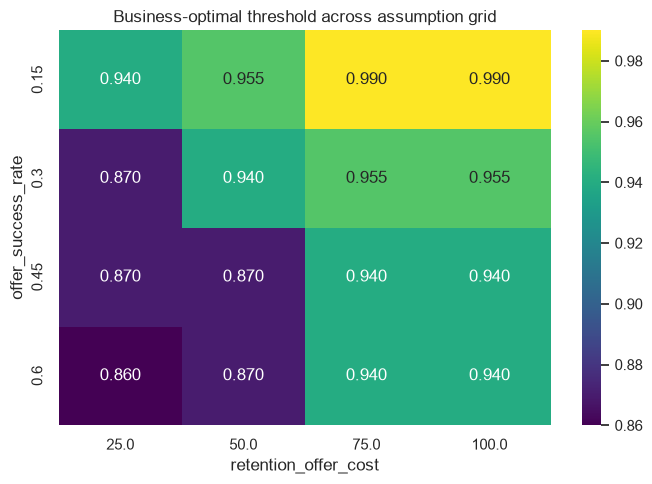

Configured assumptions (offer_success_rate=0.3, retention_offer_cost=50.0) land at threshold 0.940.
Across the grid, the optimal threshold ranges 0.860-0.990 -- moderately sensitive to these two assumptions.


In [5]:
success_rates = [0.15, 0.30, 0.45, 0.60]
costs = [25.0, 50.0, 75.0, 100.0]

sensitivity_rows = []
for sr in success_rates:
    for cost in costs:
        def _value(t, sr=sr, cost=cost):
            flagged = proba >= t
            tp = flagged & (y_true == 1)
            fp = flagged & (y_true == 0)
            return float(np.sum(sr * ltv_proxy[tp] - cost) - cost * fp.sum())
        grid = [_value(t) for t in thresholds_grid]
        best_t = float(thresholds_grid[int(np.argmax(grid))])
        sensitivity_rows.append({"offer_success_rate": sr, "retention_offer_cost": cost,
                                  "optimal_threshold": best_t, "expected_value": round(max(grid), 2)})

sensitivity_df = pd.DataFrame(sensitivity_rows)
pivot = sensitivity_df.pivot(index="offer_success_rate", columns="retention_offer_cost", values="optimal_threshold")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_title("Business-optimal threshold across assumption grid")
plt.tight_layout()
plt.show()

print(f"Configured assumptions (offer_success_rate={biz.offer_success_rate}, retention_offer_cost={biz.retention_offer_cost}) "
      f"land at threshold {business_optimal_threshold:.3f}.")
print(f"Across the grid, the optimal threshold ranges {pivot.values.min():.3f}-{pivot.values.max():.3f} "
      f"-- {'stable' if pivot.values.max()-pivot.values.min() < 0.05 else 'moderately sensitive'} to these two assumptions.")

## 5. A/B test design

A concrete, sized proposal for validating the model's real causal effect
before trusting the simulation above -- not generic advice. Grounded in
the actual flagging rate this model produces on real data.

In [6]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

flagged_rate = (proba >= business_optimal_threshold).mean()
monthly_customers = modeling_panel.groupby("reference_date").size().mean()
monthly_flagged = monthly_customers * flagged_rate

# Detect whether a retention offer moves the flagged group's churn rate by
# a meaningfully smaller effect than the config's assumed 30% success rate
# -- a 15% *relative* reduction in the flagged group's churn rate (a
# conservative, clearly-actionable effect size), not the full assumed
# effect, since a real experiment should be powered to catch a
# smaller-than-hoped effect.
baseline_churn_in_flagged = lift_df.loc[lift_df["proba"] >= business_optimal_threshold, "actual"].mean()
treatment_rate = baseline_churn_in_flagged * (1 - 0.15)

effect_size = proportion_effectsize(baseline_churn_in_flagged, treatment_rate)
power_analysis = NormalIndPower()
n_per_arm = power_analysis.solve_power(effect_size=abs(effect_size), alpha=0.05, power=0.8, ratio=1.0, alternative="two-sided")

months_needed = (2 * n_per_arm) / monthly_flagged if monthly_flagged > 0 else float("inf")

print(f"Model flags {100*flagged_rate:.2f}% of customers per month (~{monthly_flagged:.0f} of ~{monthly_customers:.0f}/month) "
      f"at the business-optimal threshold ({business_optimal_threshold:.3f}).")
print(f"Baseline churn rate within the flagged group: {100*baseline_churn_in_flagged:.2f}%")
print(f"Target effect: a 15% relative reduction (to {100*treatment_rate:.2f}%) from the retention offer.")
print(f"Required sample size: {n_per_arm:.0f} per arm ({2*n_per_arm:.0f} total) at alpha=0.05, power=0.80.")
print(f"At ~{monthly_flagged:.0f} flagged customers/month split 50/50 between control and treatment, "
      f"reaching that sample size takes approximately {months_needed:.1f} months.")

print("""
Design:
1. Randomize customers flagged at or above the business-optimal threshold
   into control (no offer) and treatment (retention offer) arms, 50/50,
   at the point of each monthly scoring run -- not by customer identity
   alone, so a customer re-flagged in a later month is re-randomized
   (avoids carryover confound from an earlier month's offer).
2. Primary outcome: actual churn within 30 days of reference_date
   (exactly `label_churn_next_30d`, once it matures) -- the same label
   this whole system predicts, so the experiment tests the thing the
   model was built to move.
3. Stop rule: pre-register the sample size computed above; no peeking-driven
   early stopping without a sequential-testing correction.
4. Guardrail metric: log the direct campaign cost against the sensitivity
   grid above during the test, so a real success-rate estimate can replace
   the config's placeholder afterward.
""")

Model flags 0.33% of customers per month (~16 of ~4844/month) at the business-optimal threshold (0.940).
Baseline churn rate within the flagged group: 38.24%
Target effect: a 15% relative reduction (to 32.50%) from the retention offer.
Required sample size: 1089 per arm (2178 total) at alpha=0.05, power=0.80.
At ~16 flagged customers/month split 50/50 between control and treatment, reaching that sample size takes approximately 136.6 months.

Design:
1. Randomize customers flagged at or above the business-optimal threshold
   into control (no offer) and treatment (retention offer) arms, 50/50,
   at the point of each monthly scoring run -- not by customer identity
   alone, so a customer re-flagged in a later month is re-randomized
   (avoids carryover confound from an earlier month's offer).
2. Primary outcome: actual churn within 30 days of reference_date
   (exactly `label_churn_next_30d`, once it matures) -- the same label
   this whole system predicts, so the experiment tests the t

## Summary

- Decile lift confirms the model concentrates real churners into the
  top-risk deciles (lift figure printed above), not just a headline
  PR-AUC number.
- Campaign simulation: the business-optimal threshold beats both
  "contact everyone" and the configured `risk_bands.medium_max` on
  expected value.
- Sensitivity grid shows how much that conclusion depends on the two
  illustrative economic assumptions -- reported honestly rather than
  presenting one number as certain.
- A concrete, sized A/B test design is ready to hand to whoever owns the
  retention campaign, grounded in this model's actual flagging rate, not
  a generic recommendation.

This closes Phase 4 (notebooks 04-06). Per PLAN.md, Phase 5 (training
pipeline + registry) is next.